# Online Retail II: каналы продаж, RFM-сегменты и удержание клиентов

**Данные:** транзакции британского онлайн-магазина подарков и товаров для дома, 01.12.2009 – 09.12.2011, 1 067 371 строка ([Kaggle](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci)).
Покупают в основном упаковками по 12, 24, 48 штук, то есть основная масса клиентов — оптовики: небольшие магазины, которые берут товар на перепродажу.

**Вопросы бизнеса:**
1. Кто наши покупатели и откуда приходит выручка?
2. Кто лучшие клиенты и сколько денег на них держится?
3. Возвращаются ли клиенты после первой покупки и в какой момент мы их теряем?

**Главное:**
- **Два канала продаж.** Клиенты с ID — опт, 87% валовой выручки. Покупатели без ID — розница, 13% (около 2,6 млн): у 82% товаров им та же позиция продаётся дороже. Розничных покупателей магазин не знает и вернуть их не может.
- **Зависимость от сегмента.** Champions — 25% клиентов и 69% выручки. Сегмент At_Risk (часто покупали, но пропали) — 9,3% выручки, около 1,6 млн.
- **Отвал после первой покупки.** В следующем месяце возвращаются только 15–30% новых клиентов. Пик возвратов приходится на ноябрь, перед Рождеством.

**Содержание:**
1. Загрузка данных
2. Очистка и поиск аномалий
3. Два канала: опт и розница
4. RFM-сегментация
5. Когортный анализ удержания

**Стек:** Python (pandas, matplotlib, seaborn)

## 1. Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('online_retail_II.zip')

In [3]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [4]:
df.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,"13,085.00",United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,"13,085.00",United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,"13,085.00",United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,"13,085.00",United Kingdom


In [5]:
df.dtypes


Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object

In [6]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [7]:
df.dtypes


Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [8]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


## 2. Очистка и поиск аномалий

Задача раздела — понять, какие строки являются реальными продажами, а какие служебными: возвраты, складские списания, бухгалтерские корректировки. Ничего не удаляем «на всякий случай», убираем только то, что мешает конкретному расчёту.

Что нашлось:

| Признак | Строк | Что это |
|---|---|---|
| Полные дубликаты | 34 335 | удалены |
| NaN в `Customer ID` | 235 151 | анонимные покупки, разобраны в разделе 3 |
| NaN в `Description` | 4 275 | нет описания с отсутствием клиента и с ценой 0 |
| invoice начинается с **C** | 19 104 | отмены и возвраты |
| invoice начинается с **A** | 6 | списание безнадёжного долга |
| Цена = 0 | 6 014 | в основном складские пометки без клиента: брак, недостача, пересорт |
| Служебные `StockCode` | — | POST, DOT, M, AMAZONFEE, BANK CHARGES и др.: доставка и комиссии, а не товары |

### Дубликаты и пропуски

In [9]:
df.shape

(1067371, 8)

In [10]:
df.duplicated().sum()

np.int64(34335)

In [11]:
df = df.drop_duplicates()

In [12]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64

In [13]:
df[df['Description'].notna()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France


In [14]:
df[df['Description'].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.00,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.00,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1060783,581199,84581,NaN,-2,2011-12-07 18:26:00,0.00,NaN,United Kingdom
1060787,581203,23406,NaN,15,2011-12-07 18:31:00,0.00,NaN,United Kingdom
1060793,581209,21620,NaN,6,2011-12-07 18:35:00,0.00,NaN,United Kingdom
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.00,NaN,United Kingdom


In [15]:
df[df['Customer ID'].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1066997,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066998,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066999,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
1067000,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


### Отрицательные и нулевые цены и количества

In [16]:
df[(df['Price'] < 0) & (df['Customer ID'].isnull())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


In [17]:
df[(df['Price'] == 0) & (df['Customer ID'].notna())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.00,"16,126.00",United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.00,"15,658.00",United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.00,"17,231.00",United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.00,"14,108.00",United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.00,"14,108.00",United Kingdom
...,...,...,...,...,...,...,...,...
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.00,"15,602.00",United Kingdom
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.00,"12,603.00",Germany
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.00,"12,444.00",Norway
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.00,"16,406.00",United Kingdom


In [18]:
df[df['Price'] == 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.00,NaN,United Kingdom
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1064015,581408,85175,NaN,20,2011-12-08 14:06:00,0.00,NaN,United Kingdom


In [19]:
df[df['Price'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


In [20]:
df[df['Quantity'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,"14,397.00",United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,"15,498.00",United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,"15,311.00",United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,"17,315.00",United Kingdom


In [21]:
df[(df['Description'].isnull()) & (df['Customer ID'].isnull())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.00,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.00,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1060783,581199,84581,NaN,-2,2011-12-07 18:26:00,0.00,NaN,United Kingdom
1060787,581203,23406,NaN,15,2011-12-07 18:31:00,0.00,NaN,United Kingdom
1060793,581209,21620,NaN,6,2011-12-07 18:35:00,0.00,NaN,United Kingdom
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.00,NaN,United Kingdom


In [22]:
df[(df['Customer ID'].isnull()) & (df['Price'] == 0)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.00,NaN,United Kingdom
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1064015,581408,85175,NaN,20,2011-12-08 14:06:00,0.00,NaN,United Kingdom


### Тип записи по первому символу счёта

Обычный счёт — цифровой. Буква **C** означает возврат, **A** — бухгалтерскую корректировку.

In [23]:
df[df['Invoice'].str[0].str.isalpha()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,"14,397.00",United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,"15,498.00",United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,"15,311.00",United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,"17,315.00",United Kingdom


In [24]:
df[(df['Invoice'].str[0] == 'C') & (df['Customer ID'].isnull())]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
5897,C489859,M,Manual,-1,2009-12-02 14:45:00,69.57,NaN,United Kingdom
5898,C489860,90029,NEW BAROQUE SMALL NECKLACE BLACK,-1,2009-12-02 14:49:00,8.50,NaN,United Kingdom
6376,C489881,21102,"CANDLE IN JAR COLLAGE , VANILLA",-31,2009-12-02 16:20:00,2.55,NaN,Nigeria
6377,C489881,72802A,ROSE SCENT CANDLE IN JEWELLED BOX,-16,2009-12-02 16:20:00,4.25,NaN,Nigeria
11553,C490307,POST,POSTAGE,-1,2009-12-04 14:49:00,8.97,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1017668,C578097,22112,CHOCOLATE HOT WATER BOTTLE,-48,2011-11-22 17:31:00,4.25,NaN,United Kingdom
1040445,C579757,47469,ASSORTED SHAPES PHOTO CLIP SILVER,-24,2011-11-30 14:56:00,0.65,NaN,United Kingdom
1041915,C579907,22169,FAMILY ALBUM WHITE PICTURE FRAME,-2,2011-12-01 08:48:00,7.65,NaN,EIRE
1050062,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,"11,586.50",NaN,United Kingdom


In [25]:
df['Invoice'].str[0].value_counts()

Invoice
5    906634
4    107292
C     19104
A         6
Name: count, dtype: int64

In [26]:
df[df['Invoice'].str[0] == 'A']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


### Страны и самые частые товары

In [27]:
df['Country'].value_counts()

Country
United Kingdom          948321
EIRE                     17667
Germany                  17339
France                   14025
Netherlands               5137
Spain                     3754
Switzerland               3175
Belgium                   3110
Portugal                  2528
Australia                 1890
Channel Islands           1646
Italy                     1507
Sweden                    1362
Norway                    1308
Cyprus                    1157
Finland                   1049
Austria                    938
Denmark                    797
Unspecified                752
Greece                     663
Japan                      565
USA                        535
Poland                     527
United Arab Emirates       500
Israel                     368
Hong Kong                  360
Singapore                  346
Malta                      299
Canada                     228
Iceland                    222
RSA                        169
Lithuania                  154


In [28]:
df['StockCode'].value_counts().head(20)

StockCode
85123A    5653
22423     4306
85099B    4132
21212     3209
20725     3170
84879     2870
47566     2733
21232     2666
22383     2469
22197     2465
20727     2447
21931     2387
22386     2294
22411     2232
22469     2225
22382     2194
84991     2193
22384     2175
21080     2168
22139     2164
Name: count, dtype: int64

### Служебные записи склада

Описания, которые встречаются один раз и написаны строчными буквами (`water damage`, `wrong ctn size`), — это пометки склада, а не названия товаров.

In [29]:
df[(df['Price'] == 0) & (df['Customer ID'].isnull()) & (df['Description'].notna())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.00,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1060797,581213,22576,check,-30,2011-12-07 18:38:00,0.00,NaN,United Kingdom
1062371,581226,23090,missing,-338,2011-12-08 09:56:00,0.00,NaN,United Kingdom
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom


In [30]:
df[(df['Customer ID'].isnull()) & (df['Description'].notna())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1066997,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066998,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
1066999,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
1067000,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


In [31]:
value_count = df['Description'].value_counts()
singl = value_count[value_count == 1]
print(singl)

Description
water damage                          1
sold as set by dotcom                 1
stock creditted wrongly               1
OWLS CHARLOTTE BAG                    1
sold as set on dotcom and amazon      1
                                     ..
SPOTTY CAT DOORSTOP                   1
SET OF 4 KNICK KNACK TINS  DOILEY     1
Dagamed                               1
SILVER PURSE GOLD PINK BUTTERFLY      1
wrong ctn size                        1
Name: count, Length: 390, dtype: int64


## 3. Два канала: опт и розница

Почти четверть строк без `Customer ID`. Прежде чем исключать их, проверяем: это сбой записи или отдельный тип покупателей?

Флаг `Customer ID null` (True — аноним) и доля анонимных строк внутри каждого счёта. Если доля всегда 0 или 1, значит, клиент не теряется у отдельных строк: счёт целиком либо с клиентом, либо без.

In [32]:
df['Customer ID null'] = df['Customer ID'].isnull()
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False


In [33]:
df.groupby('Invoice')['Customer ID null'].mean().value_counts()

Customer ID null
0.00    44876
1.00     8752
Name: count, dtype: int64

In [34]:
# True - покупатели без ID 
# False - покупатели с ID
df.groupby('Customer ID null')[['Quantity', 'Price']].median()

,Quantity,Price
Customer ID null,,
False,5.00,1.95
True,1.00,3.29


### Проверка на одном товаре

Разница в медианной цене может объясняться тем, что группы покупают разные товары. Честное сравнение — один и тот же `StockCode` в двух группах.

In [35]:
one_item = df[(df['StockCode'] == '22411') & (df['Price'] > 0)]

In [36]:
one_item.groupby('Customer ID null')[['Price']].median()

,Price
Customer ID null,
False,1.95
True,4.13


#### Вот и подтверждение для одного товара: 
- #### покупатели с ID берут по 1,95
- #### анонимы по 4,13, почти вдвое дороже.

### Таблица продаж `sales`

Для расчётов выручки оставляем только реальные продажи: цена больше 0, без возвратов (C) и бухгалтерских записей (A), только товарные коды (начинаются с цифры). Выручка строки = количество × цена.

In [37]:
# колонка revenue - сумма строки
df['Revenue'] = df['Quantity'] * df['Price']
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00


In [38]:
sales = df[(df['Price'] > 0) & (df['Invoice'].str[0] != 'C') & (df['Invoice'].str[0] != 'A') & (df['StockCode'].str[0].str.isdigit())]
sales.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00


### Цены на всём ассортименте

Медианная цена каждого товара в двух группах, только по товарам, которые продаются обеим (4 095 позиций).

In [39]:
prices = sales.groupby(['StockCode', 'Customer ID null'])["Price"].median().unstack().dropna()

In [40]:
(prices[True] > prices[False]).mean()

np.float64(0.8185592185592185)

#### У 82% товаров анонимам цена выше

In [41]:
(prices[True] == prices[False]).mean()

np.float64(0.07472527472527472)

#### У 7,5% товаров цена одинаковая

In [42]:
(prices[True] < prices[False]).mean()

np.float64(0.10671550671550671)

#### У 11% товаров цена ниже

## Вывод: 
#### В сумме 100%, так что картина полная. Теперь это не впечатление от одного товара, а подтверждение на всём ассортименте: у магазина два канала с разными ценами. Опт для клиентов с ID и розница для анонимов.

### Выручка по каналам

Сначала сумма по сырому `df`, чтобы увидеть, насколько её искажают возвраты и счета на A. Затем валовая выручка по `sales`.

In [43]:
df.groupby('Customer ID null')[['Quantity', 'Revenue']].sum()

,Quantity,Revenue
Customer ID null,,
False,10055729,"16,289,991.29"
True,354050,"2,565,542.41"


In [44]:
df_without_A = df[df['Invoice'].str[0] != 'A']
df[df['Invoice'].str[0] == 'A']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",NaN,United Kingdom,True,"-53,594.36"
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",NaN,United Kingdom,True,"-44,031.79"
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",NaN,United Kingdom,True,"-38,925.87"
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom,True,"11,062.06"
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom,True,"-11,062.06"
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom,True,"-11,062.06"


In [45]:
df_without_A.groupby('Customer ID null')[['Quantity', 'Price', 'Revenue']].sum()

,Quantity,Price,Revenue
Customer ID null,,,
False,10055729,"2,954,354.03","16,289,991.29"
True,354044,"1,959,667.14","2,713,156.49"


In [46]:
sales.groupby('Customer ID null')['Revenue'].sum()

Customer ID null
False   17,068,567.97
True     2,574,124.18
Name: Revenue, dtype: float64

#### У клиентов с ID вышло 17,07 млн, а на сыром df было 16,29 млн. Разница в том, что в sales нет возвратов, их минус раньше уменьшал сумму. Сейчас имеем валовую выручку, до вычета возвратов.

In [47]:
revenue_by_channel = sales.groupby('Customer ID null')['Revenue'].sum()
revenue_by_channel / revenue_by_channel.sum() * 100

Customer ID null
False   86.90
True    13.10
Name: Revenue, dtype: float64

### Опт 87%, розница 13%. Анонимы дают около 2,6 млн из 19,6.

## Сравним три цифры по анонимам: 
- ### 16% счетов, 23% строк и только 13% денег. В деньгах их меньше всего. Хотя платят они почти вдвое дороже, берут по одной штуке.
- ### Строка оптовика — это упаковка из 12 или 24 штук, и она стоит больше, даже при цене в два раза ниже.

## Выводы для бизнеса:
- ### Покупатели делятся на два канала по наличию ID: клиенты с ID — опт, покупатели без ID — розница. Опт даёт 87% валовой выручки (17,07 млн), поэтому дальнейший RFM-анализ по клиентам с ID покрывает основную часть денег.
- ### Розница — 13% выручки, около 2,6 млн. При этом это 16% счетов и 23% строк: розничные покупатели берут по одной штуке, поэтому в деньгах их доля меньше. Об этих покупателях магазин ничего не знает и не может предложить им персональные условия или вернуть рассылкой. Мотивацией к регистрации может стать скидка или бонус за создание аккаунта.

### Гипотеза: анонимный канал — это сайт

В анонимных счетах встречается строка DOT (DOTCOM POSTAGE — доставка заказа с сайта). Считаем, сколько счетов с DOT в каждой группе.

In [48]:
orders = df[df['Invoice'].str[0].str.isdigit()].copy()

In [49]:
orders['is_dot'] = orders['StockCode'] == 'DOT'
orders

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue,is_dot
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00,False
...,...,...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,False,12.60,False
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,False
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,False
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France,False,14.85,False


In [50]:
invoices = orders.groupby('Invoice').agg({
    'Customer ID null': 'first',
    'is_dot': 'max'
})
invoices

,Customer ID null,is_dot
Invoice,,
489434,False,False
489435,False,False
489436,False,False
489437,False,False
489438,False,False
...,...,...
581583,False,False
581584,False,False
581585,False,False


In [51]:
invoices.groupby('Customer ID null')['is_dot'].sum()

Customer ID null
False      16
True     1406
Name: is_dot, dtype: int64

**Вывод по гипотезе:**
- Счетов с доставкой с сайта (DOT) у клиентов с ID всего 16, у анонимов — 1 406. То есть 99% заказов с доставкой с сайта анонимные: связь «аноним ↔ сайт» есть.
- Но DOT встречается только в 17% анонимных счетов, в остальных 83% его нет. Утверждать, что все анонимы покупают через сайт, нельзя — **гипотеза подтверждена частично**.
- Что может скрываться в остальных 83%: бесплатная доставка от суммы заказа, доставка под кодом POST или покупки не через сайт. Это можно проверить отдельно.

## 4. RFM-сегментация

Оцениваем каждого клиента по трём показателям:
- **Recency** — сколько дней прошло с последней покупки;
- **Frequency** — сколько было покупок (уникальных счетов);
- **Monetary** — сколько денег принёс.

Берём только клиентов с ID: у анонимов нет истории, их нельзя сегментировать и вернуть рассылкой. Это 87% выручки.

In [52]:
# оставляем только клиентов с ID, анонимов для RFM мы уже обоснованно исключили.
rfm_data = sales[sales['Customer ID null'] == False].copy()
sales[sales['Customer ID null'] == False].copy()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00
...,...,...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France,False,10.20
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,False,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60


In [53]:
# Данные заканчиваются 9 декабря 2011, поэтому «сегодня» для нас — это последняя дата в данных плюс один день.
snapshot_date = sales['InvoiceDate'].max() + pd.Timedelta(days=1)

In [54]:
# Группируем по клиенту:
# InvoiceDate - дату последней покупки
# Invoice - число покупок 
# Revenue -  сумма денег
rfm = rfm_data.groupby('Customer ID').agg({'InvoiceDate': 'max', 'Invoice': 'nunique', 'Revenue': 'sum'})
rfm

,InvoiceDate,Invoice,Revenue
Customer ID,,,
"12,346.00",2011-01-18 10:01:00,3,"77,352.96"
"12,347.00",2011-12-07 15:52:00,8,"4,921.53"
"12,348.00",2011-09-25 13:13:00,5,"1,658.40"
"12,349.00",2011-11-21 09:51:00,3,"3,678.69"
"12,350.00",2011-02-02 16:01:00,1,294.40
...,...,...,...
"18,283.00",2011-12-06 12:02:00,22,"2,658.95"
"18,284.00",2010-10-04 11:33:00,1,411.68
"18,285.00",2010-02-17 10:24:00,1,377.00


In [55]:
# переименнуем колонки
rfm = rfm.rename(columns={
    'InvoiceDate': 'LastPurchase',
    'Invoice': 'Frequency',
    'Revenue': 'Monetary'
})

In [56]:
# посчитаем давность
rfm['Recency'] = (snapshot_date - rfm['LastPurchase']).dt.days

In [57]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,"5,852.00","5,852.00","5,852.00"
mean,200.20,6.25,"2,916.71"
std,208.51,12.75,"14,306.85"
min,1.00,1.00,2.95
25%,25.00,1.00,339.57
50%,95.00,3.00,856.02
75%,379.00,7.00,"2,241.03"
max,739.00,373.00,"580,987.04"


1. **Recency - давность:** Медиана 95 дней. Обращаю внимание на 75 % - это 379 дней. Значит, четверть клиентов не покупала больше года, и это, скорее всего, уже потерянные клиенты. А на другом краю 25 % = 25 дней: четверть клиентов активна прямо сейчас.
2. **Frequency - частота:** Медиана 3, а 25 % = 1. Значит, минимум четверть клиентов купила один раз и больше не вернулась. Для оптовика это повод задуматься: почему пробный заказ не превращается в постоянного клиента? А максимум 373 покупки за два года, почти через день. Это крупный постоянный оптовик!
3. **Monetary - деньги:** Среднее 2 917 в 3,4 раза больше медианы 856. Значит имеем несколько очень крупных клиентов. Максимум 580 987: один клиент приносит около 3,4 % всей выручки от клиентов с ID.

#### Теперь отсортируем клиентов и поделим их на 5 равных групп и сделаем разбаловку:

In [58]:
rfm['R'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

In [59]:
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

In [60]:
rfm['M'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

In [61]:
display(rfm[['R', 'F', 'M']].head())
rfm['F'].value_counts()

,R,F,M
Customer ID,,,
"12,346.00",2,3,5
"12,347.00",5,4,5
"12,348.00",3,4,4
"12,349.00",5,3,5
"12,350.00",2,1,2


F
1    1171
5    1171
2    1170
3    1170
4    1170
Name: count, dtype: int64

#### Деление по сегментам:
1) **Чемпионы (Champions)** - бизнесу лучше беречь и давать лучшие условия
2) **Лояльные (Loyal)** - бизнесу лучше поддерживать их и допродавать им товар
3) **Новички (New)** - нужно превратить в постоянных клиентов
4) **Под угрозой (At Risk)** - тот сегмент, которые часто покупали, но перестали => срочно возвращать их
5) **Спящие (Hibernating)** - бизнесу стоит напомнить им о себе
6) **Потерянные (Lost)** - заниматься простым привлечением или дешевой рассылкой, ну или совсем отпустить

In [62]:
# переведу баллы в обычные числа
rfm[['R', 'F', 'M']] = rfm[['R', 'F', 'M']].astype(int)

In [63]:
# создадим функцию, которая выделяет сегменты клиентов
def get_segment(row) -> str:
    R = row['R']
    F = row['F']
    if R >= 4 and F >= 4:
        return 'Champions' 
    elif R >= 3 and F >= 3:
        return 'Loyal'
    elif R >= 4:
        return 'New'
    elif R <= 2 and F >= 3:
        return 'At_Risk'
    elif R == 2 or R == 3:
        return 'Hibernating'
    else:
        return 'Lost'

In [64]:
rfm['Segment'] = rfm.apply(get_segment, axis=1)

In [65]:
rfm['Segment'].value_counts()

Segment
Champions      1476
Loyal          1207
Hibernating    1001
Lost            889
At_Risk         828
New             451
Name: count, dtype: int64

In [66]:
sum_segment = rfm.groupby('Segment')['Monetary'].sum()
(rfm.groupby('Segment')['Monetary'].sum()).sort_values(ascending=False)

Segment
Champions     11,816,435.50
Loyal          2,421,467.14
At_Risk        1,592,996.03
Hibernating      462,077.00
New              416,414.78
Lost             359,177.52
Name: Monetary, dtype: float64

In [67]:
# доля денег
revenue_share = (sum_segment/sum_segment.sum()) * 100
((sum_segment/sum_segment.sum()) * 100).sort_values(ascending=False)

Segment
Champions     69.23
Loyal         14.19
At_Risk        9.33
Hibernating    2.71
New            2.44
Lost           2.10
Name: Monetary, dtype: float64

In [68]:
# доля клиентов
clients_share = rfm['Segment'].value_counts(normalize=True) * 100
rfm['Segment'].value_counts(normalize=True) * 100

Segment
Champions     25.22
Loyal         20.63
Hibernating   17.11
Lost          15.19
At_Risk       14.15
New            7.71
Name: proportion, dtype: float64

In [69]:
segments = (pd.DataFrame({'Клиенты, %': clients_share, 'Выручка, %': revenue_share}).sort_values('Выручка, %', ascending=False)).round(1)

### 1. Champions: 25% клиентов и 69% денег. Что это значит?
**Доля денег у них в 2,7 раза больше доли клиентов. Отсюда два следствия: это главный актив, и одновременно это риск. Магазин сильно зависит от небольшой группы, и потеря даже нескольких крупных клиентов ощутимо ударит по выручке.**
### 2. At_Risk: 9,3% денег, около 1,6 млн. Чем опасно и что делать?
**Среди всех является одним из самых интересных сегментов. Правда есть опасность, что выручка с этого сегмента может дать значительные потери, если тенденция ухода продолжится. Магазин потеряет около 1,6 млн (9,3% выручки). (ДОП. Анализ: взять список 828 клиентов, отсортировать по Monetary и начать с самых крупных. Например, клиент 12346 с 77 тысячами. Для оптового бизнеса это скорее звонок менеджера, чем рассылка со скидкой.)**
### 3. Hibernating, Lost, New: 40% клиентов и 7% денег. Как к ним относиться?
**С новичками заняться активным привлечением, главная задача, добиться второй покупки, чтобы пошёл прогресс. С остальными делать наименьший акцент, на них не тратим дорогие ресурсы (личные звонки, индивидуальные скидки), но держим дешёвый автоматический контакт, например рассылку.**

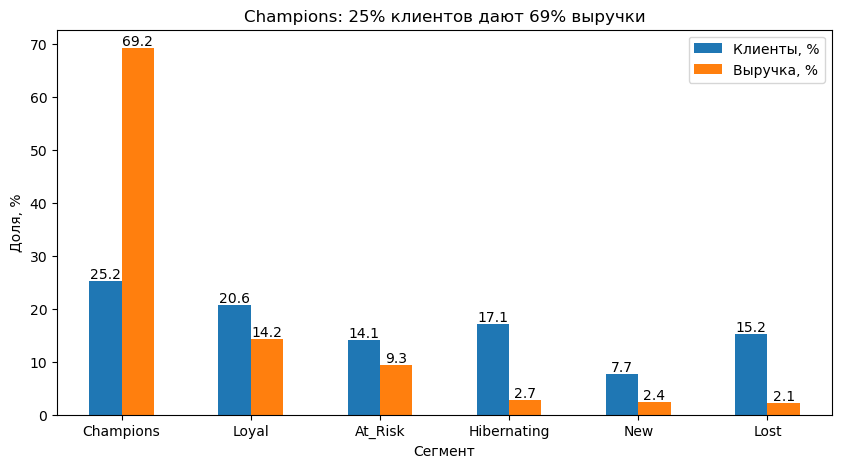

In [70]:
ax = segments.plot(kind='bar', figsize=(10, 5), rot=0)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Champions: 25% клиентов дают 69% выручки')
plt.xlabel('Сегмент')
plt.ylabel('Доля, %')
plt.show()

## 5. Когортный анализ удержания

**Когорта** — клиенты, которые сделали первую покупку в одном и том же месяце. Для каждой когорты смотрим, какая доля клиентов купила снова через 1, 2, 3… месяца.

Как читать тепловую карту:
- строка — месяц первой покупки;
- столбец — сколько месяцев прошло с первой покупки (0 — месяц первой покупки, там всегда 100%);
- диагональ — один и тот же календарный месяц для разных когорт.

In [71]:
# Месяц покупки
rfm_data['OrderMonth'] = rfm_data['InvoiceDate'].dt.to_period('M')

In [72]:
# Месяц когорты
rfm_data['CohortMonth'] = rfm_data.groupby('Customer ID')['OrderMonth'].transform('min')

In [73]:
rfm_data

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue,OrderMonth,CohortMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40,2009-12,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,2009-12,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,2009-12,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80,2009-12,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00,2009-12,2009-12
...,...,...,...,...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France,False,10.20,2011-12,2011-08
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,False,12.60,2011-12,2011-08
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,2011-12,2011-08
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,2011-12,2011-08


In [74]:
display(rfm_data.shape)
print('\n')
display(rfm_data['OrderMonth'].nunique())
print('\n')
display(rfm_data['CohortMonth'].value_counts().sort_index())

(776577, 12)

25

CohortMonth
2009-12    309322
2010-01     63527
2010-02     53316
2010-03     64300
2010-04     28905
2010-05     22183
2010-06     26732
2010-07     20010
2010-08     16685
2010-09     19378
2010-10     31884
2010-11     25367
2010-12      3432
2011-01      6002
2011-02      7359
2011-03     12362
2011-04      6903
2011-05      6034
2011-06      6410
2011-07      7412
2011-08     10096
2011-09     10130
2011-10     11321
2011-11      6882
2011-12       625
Freq: M, Name: count, dtype: int64

In [75]:
# Номера месяца «жизни» клиента
order_year = rfm_data['OrderMonth'].dt.year
order_month = rfm_data['OrderMonth'].dt.month
cohort_year = rfm_data['CohortMonth'].dt.year
cohort_month = rfm_data['CohortMonth'].dt.month

In [76]:
rfm_data['CohortIndex'] = (order_year - cohort_year) * 12 + (order_month - cohort_month)

In [77]:
rfm_data

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue,OrderMonth,CohortMonth,CohortIndex
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40,2009-12,2009-12,0
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,2009-12,2009-12,0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00,2009-12,2009-12,0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80,2009-12,2009-12,0
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00,2009-12,2009-12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France,False,10.20,2011-12,2011-08,4
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,False,12.60,2011-12,2011-08,4
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,2011-12,2011-08,4
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60,2011-12,2011-08,4


In [78]:
rfm_data['CohortMonth']

0          2009-12
1          2009-12
2          2009-12
3          2009-12
4          2009-12
            ...   
1067365    2011-08
1067366    2011-08
1067367    2011-08
1067368    2011-08
1067369    2011-08
Name: CohortMonth, Length: 776577, dtype: period[M]

### Матрица удержания

Считаем уникальных клиентов в каждой паре «когорта × номер месяца», делим на размер когорты (столбец 0). Сверка: сумма столбца 0 = 5 852, все клиенты из RFM.

In [79]:
# Матрица-треугольник
cohort_counts = rfm_data.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().unstack()
cohort_counts

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,951.00,333.00,317.00,404.00,360.00,342.00,358.00,327.00,321.00,344.00,...,288.00,250.00,288.00,270.00,246.00,242.00,298.00,289.00,386.00,187.00
2010-01,368.00,79.00,118.00,116.00,100.00,114.00,99.00,86.00,105.00,120.00,...,56.00,90.00,75.00,71.00,74.00,93.00,73.00,93.00,21.00,NaN
2010-02,375.00,88.00,85.00,110.00,92.00,74.00,72.00,108.00,96.00,104.00,...,75.00,60.00,61.00,54.00,86.00,86.00,62.00,22.00,NaN,NaN
2010-03,441.00,84.00,102.00,107.00,102.00,90.00,109.00,135.00,122.00,48.00,...,75.00,77.00,69.00,78.00,90.00,94.00,34.00,NaN,NaN,NaN
2010-04,294.00,56.00,56.00,47.00,54.00,65.00,81.00,78.00,31.00,32.00,...,46.00,41.00,44.00,53.00,67.00,17.00,NaN,NaN,NaN,NaN
2010-05,255.00,40.00,43.00,45.00,45.00,65.00,54.00,32.00,15.00,21.00,...,32.00,35.00,42.00,39.00,12.00,NaN,NaN,NaN,NaN,NaN
2010-06,267.00,47.00,50.00,55.00,62.00,76.00,34.00,24.00,22.00,30.00,...,33.00,35.00,54.00,13.00,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,185.00,29.00,34.00,55.00,54.00,26.00,21.00,27.00,27.00,21.00,...,32.00,44.00,15.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,163.00,32.00,47.00,53.00,27.00,19.00,16.00,21.00,22.00,21.00,...,32.00,12.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [80]:
cohort_counts[0]

CohortMonth
2009-12   951.00
2010-01   368.00
2010-02   375.00
2010-03   441.00
2010-04   294.00
2010-05   255.00
2010-06   267.00
2010-07   185.00
2010-08   163.00
2010-09   239.00
2010-10   375.00
2010-11   326.00
2010-12    76.00
2011-01    72.00
2011-02   125.00
2011-03   179.00
2011-04   106.00
2011-05   111.00
2011-06   108.00
2011-07   101.00
2011-08   107.00
2011-09   188.00
2011-10   221.00
2011-11   191.00
2011-12    28.00
Freq: M, Name: 0, dtype: float64

In [81]:
# какая доля когорты вернулась в этот месяц
retention = ((cohort_counts.div(cohort_counts[0], axis=0)) * 100).round(1)
retention

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.00,35.00,33.30,42.50,37.90,36.00,37.60,34.40,33.80,36.20,...,30.30,26.30,30.30,28.40,25.90,25.40,31.30,30.40,40.60,19.70
2010-01,100.00,21.50,32.10,31.50,27.20,31.00,26.90,23.40,28.50,32.60,...,15.20,24.50,20.40,19.30,20.10,25.30,19.80,25.30,5.70,NaN
2010-02,100.00,23.50,22.70,29.30,24.50,19.70,19.20,28.80,25.60,27.70,...,20.00,16.00,16.30,14.40,22.90,22.90,16.50,5.90,NaN,NaN
2010-03,100.00,19.00,23.10,24.30,23.10,20.40,24.70,30.60,27.70,10.90,...,17.00,17.50,15.60,17.70,20.40,21.30,7.70,NaN,NaN,NaN
2010-04,100.00,19.00,19.00,16.00,18.40,22.10,27.60,26.50,10.50,10.90,...,15.60,13.90,15.00,18.00,22.80,5.80,NaN,NaN,NaN,NaN
2010-05,100.00,15.70,16.90,17.60,17.60,25.50,21.20,12.50,5.90,8.20,...,12.50,13.70,16.50,15.30,4.70,NaN,NaN,NaN,NaN,NaN
2010-06,100.00,17.60,18.70,20.60,23.20,28.50,12.70,9.00,8.20,11.20,...,12.40,13.10,20.20,4.90,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.00,15.70,18.40,29.70,29.20,14.10,11.40,14.60,14.60,11.40,...,17.30,23.80,8.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.00,19.60,28.80,32.50,16.60,11.70,9.80,12.90,13.50,12.90,...,19.60,7.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


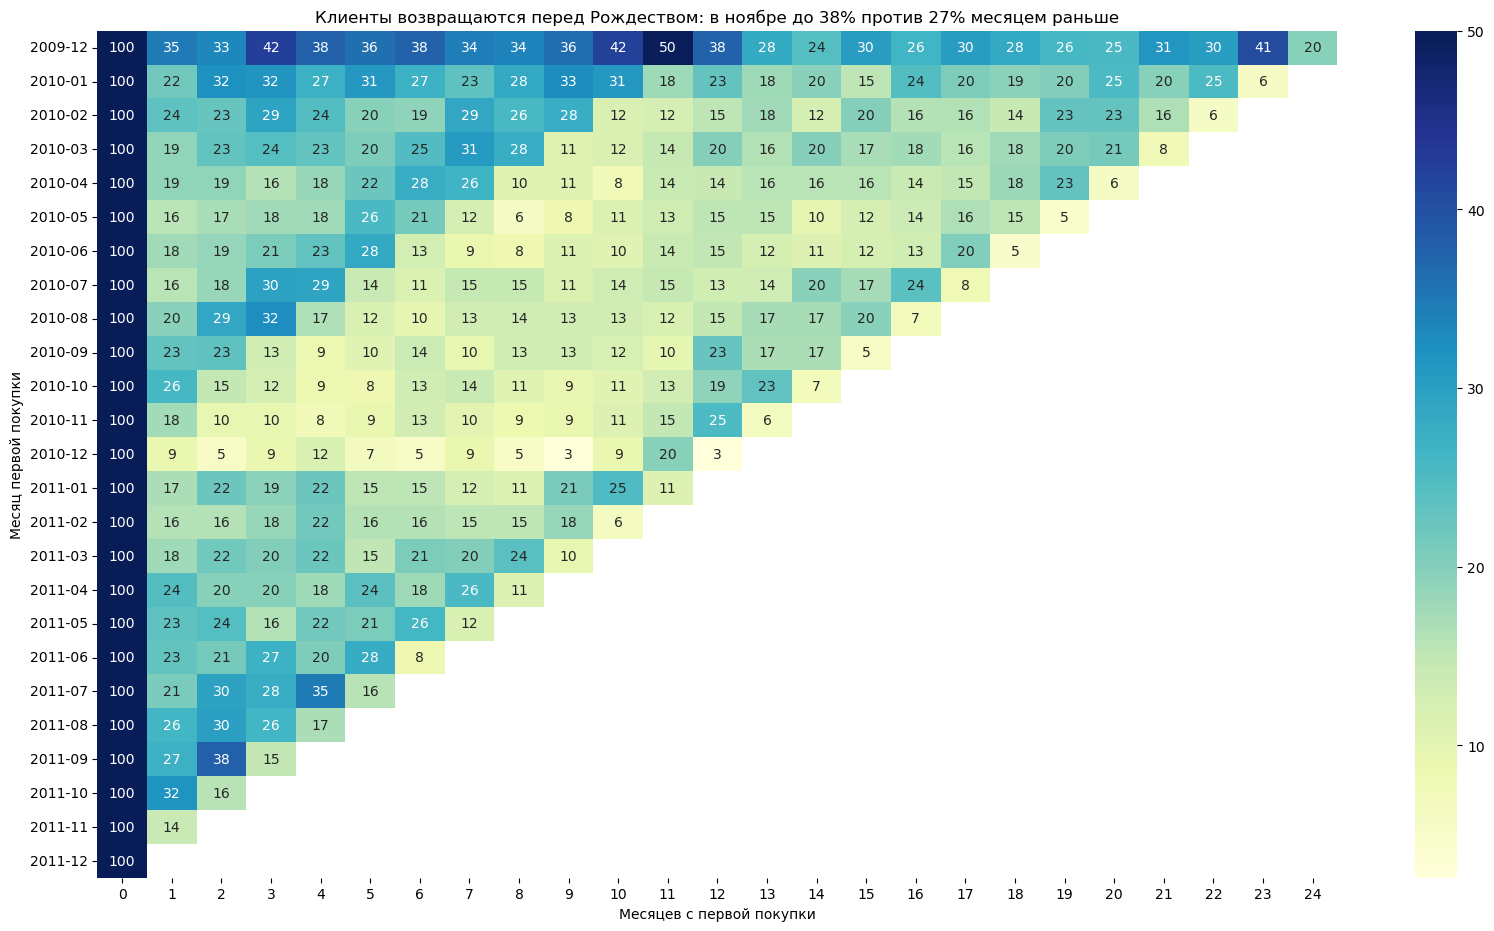

In [82]:
# Тепловая карта
plt.figure(figsize=(20,11))
sns.heatmap(retention, fmt='.0f', cmap='YlGnBu', vmax=50, annot=True)
plt.title('Клиенты возвращаются перед Рождеством: в ноябре до 38% против 27% месяцем раньше')
plt.xlabel('Месяцев с первой покупки')
plt.ylabel('Месяц первой покупки')
plt.show()

## Выводы:
### Удержание клиентов: когда возвращаются и где мы их теряем
1. Первая важная потеря происходит после первой покупки. После неё в следующем месяце возвращаются только 15-30 % новых клиентов. Имеем сходство с RFM анализом, где около четверти клиентов за весь период купили не более одного раза. Предлагаю проводить работы по совершению клиентом второго заказа в первый месяц: дополнительные звонки менеджеров, предложения закупок.
2. Закономерность возвращения к Рождеству. Пик возвратов приходится на ноябрь, и это видно внутри одной и той же когорты. У когорты 2009-12 в ноябре 2010 вернулось 50 % клиентов против 33-42 % в январе-сентябре того же года, в ноябре 2011 - 41 % против 30 % в октябре и 25-31 % в марте-сентябре. У когорты 2011-09 в ноябре вернулось 38 % против 27 % в октябре. В декабре 2010 у весенних когорт провал до 10-12 % - вероятно, закупились заранее, в ноябре. Как итог, лучшее время подготовки - август и сентябрь: пополнять склад и готовить предложения к сезону.
3. Клиенты пришедшие в декабре 2010 (76 клиентов) в большинстве своём практически не остаются (3-12 % удержания). Гипотеза: что пришедшие в декабре - это разовые покупатели, а не те, кто закупается оптом. Нужно проверить их средний чек и какой у этих когорт состав заказов.

Есть некоторые ограничения:
- у когорты 2009-12 мы видим значительное отличие в большую сторону от других. Скорее всего это старые клиенты, которые покупали ещё до начала имеющихся данных. Поэтому она не подходит для сравнения.
- Декабрь 2011 представлен только 9 днями данных, поэтому последняя диагональ карты светлая, а когорта 2011-12 маленькая. Это не отток
- Данная тепловая карта показывает долю вернувшихся клиентов, а не деньги: сколько выручки приносит ноябрьский пик не считали

In [83]:
import sqlite3
conn = sqlite3.connect('retail.db')

In [84]:
sales.to_sql('sales', conn, if_exists='replace', index=False)

1003214

In [85]:
sales

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Customer ID null,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,30.00
...,...,...,...,...,...,...,...,...,...,...
1067365,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France,False,10.20
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,False,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,False,16.60


In [86]:
retention_long = retention.stack().reset_index(name='Retention')
retention_long

,CohortMonth,CohortIndex,Retention
0,2009-12,0,100.00
1,2009-12,1,35.00
2,2009-12,2,33.30
3,2009-12,3,42.50
4,2009-12,4,37.90
...,...,...,...
320,2011-10,1,31.70
321,2011-10,2,15.80
322,2011-11,0,100.00
323,2011-11,1,14.10


In [87]:
# Убираем Customer ID из индекса для Power BI
rfm_bi = rfm.reset_index()
display(rfm_bi)
rfm_bi.nunique()

,Customer ID,LastPurchase,Frequency,Monetary,Recency,R,F,M,Segment
0,"12,346.00",2011-01-18 10:01:00,3,"77,352.96",326,2,3,5,At_Risk
1,"12,347.00",2011-12-07 15:52:00,8,"4,921.53",2,5,4,5,Champions
2,"12,348.00",2011-09-25 13:13:00,5,"1,658.40",75,3,4,4,Loyal
3,"12,349.00",2011-11-21 09:51:00,3,"3,678.69",19,5,3,5,Loyal
4,"12,350.00",2011-02-02 16:01:00,1,294.40,310,2,1,2,Hibernating
...,...,...,...,...,...,...,...,...,...
5847,"18,283.00",2011-12-06 12:02:00,22,"2,658.95",4,5,5,4,Champions
5848,"18,284.00",2010-10-04 11:33:00,1,411.68,432,1,2,2,Lost
5849,"18,285.00",2010-02-17 10:24:00,1,377.00,661,1,2,2,Lost
5850,"18,286.00",2010-08-20 11:57:00,2,"1,246.43",477,1,3,4,At_Risk


Customer ID     5852
LastPurchase    5702
Frequency         86
Monetary        5755
Recency          674
R                  5
F                  5
M                  5
Segment            6
dtype: int64

In [88]:
# Выгрузка для Power BI
sales.to_csv('sales.csv', index=False)
rfm_bi.to_csv('rfm_bi.csv', index=False)
retention_long.to_csv('retention_long.csv', index=False)